# Customer Attrition Analysis: IBM Telco Customer Churn

**Business question:** which customers are most likely to leave, how concentrated is that risk, and
what should the business test to keep more of them?

**Data:** 7,043 customers of a fictional telecom provider (IBM sample data), one row per customer, 21 columns.
`Churn = "Yes"` means the customer left. In IBM's description that's within the last month.

**How this notebook is organised**
1. Data audit: what's in the file, and what needs fixing
2. Segment analysis: who leaves more often, and how strong each pattern is
3. Risk cohort: one small group that accounts for a large share of the customers who left
4. Modeling: can we rank customers by risk better than chance?
5. Charts
6. Business recommendation

All logic lives in `src/` so the notebook and the scripts always agree. This notebook only calls those functions and explains the results.

### Setup
We point Python at the `src/` folder and import the project's own functions. We also turn off pandas'
row truncation so the tables show completely.

In [1]:
import sys
from pathlib import Path

SRC = Path.cwd().parent / "src" if Path.cwd().name == "notebooks" else Path.cwd() / "src"
sys.path.insert(0, str(SRC))

import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_rows", 50)
pd.set_option("display.width", 120)

import audit, segments, cohort, model, charts
from data import load_raw, clean, churned

## 1. Data audit

### 1.1 Shape, column types, missing values
First we read the file exactly as stored, without fixing anything. We check how many rows and columns
there are, what type pandas gave each column, and how many values are missing.

In [2]:
raw = load_raw()
profile = audit.basic_profile(raw)
print("Rows, columns:", profile["shape"])
print("Total missing values reported by isnull():", int(profile["null_counts"].sum()))
profile["dtypes"].to_frame("dtype")

Rows, columns: (7043, 21)
Total missing values reported by isnull(): 0


,dtype
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


### 1.2 The hidden problem in TotalCharges
`TotalCharges` should be a number (dollars billed so far), but it's stored as **text**. The null check
above reported zero missing values, and that's misleading: some customers have a blank string `" "`,
which pandas doesn't count as missing. Here we find those blanks and look at who they are.

In [3]:
issue = audit.total_charges_issue(raw)
print("TotalCharges stored as text:", issue["total_charges_is_text"])
print("Missing values isnull() finds in TotalCharges:", issue["total_charges_nulls"])
print("Blank-string TotalCharges values:", issue["blank_count"])
print("Every blank belongs to a customer with tenure 0:", issue["all_blanks_tenure_zero"])
print("Customers with tenure 0 in the whole file:", issue["tenure_zero_count"])
issue["blank_rows"]

TotalCharges stored as text: True
Missing values isnull() finds in TotalCharges: 0
Blank-string TotalCharges values: 11
Every blank belongs to a customer with tenure 0: True
Customers with tenure 0 in the whole file: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Why the blanks exist:** every blank belongs to a customer with `tenure = 0`, and every tenure-0 customer
has a blank. These customers signed up but haven't been billed yet, so the true amount billed so far is
**$0**, not "unknown".

**What we do:** fill the blanks with 0 and convert the column to a number. We **don't drop** these rows.
They're real customers, and dropping them would quietly change every rate in this analysis.

In [4]:
df = clean(raw)
print("Rows after cleaning:", len(df), "| rows before:", len(raw))
print("TotalCharges type now:", df["TotalCharges"].dtype)
print("Customers with TotalCharges = 0:", int((df["TotalCharges"] == 0).sum()))

Rows after cleaning: 7043 | rows before: 7043
TotalCharges type now: float64
Customers with TotalCharges = 0: 11


### 1.3 Duplicates and inconsistent categories
We check whether any customer ID appears twice, then list every value of each text column to catch typos
or near-duplicates.

In [5]:
print("Duplicate customerIDs:", audit.duplicate_ids(raw))
for column, values in audit.category_values(raw).items():
    print(f"{column:17s} {values}")

Duplicate customerIDs: 0
gender            ['Female', 'Male']
Partner           ['No', 'Yes']
Dependents        ['No', 'Yes']
PhoneService      ['No', 'Yes']
MultipleLines     ['No', 'No phone service', 'Yes']
InternetService   ['DSL', 'Fiber optic', 'No']
OnlineSecurity    ['No', 'No internet service', 'Yes']
OnlineBackup      ['No', 'No internet service', 'Yes']
DeviceProtection  ['No', 'No internet service', 'Yes']
TechSupport       ['No', 'No internet service', 'Yes']
StreamingTV       ['No', 'No internet service', 'Yes']
StreamingMovies   ['No', 'No internet service', 'Yes']
Contract          ['Month-to-month', 'One year', 'Two year']
PaperlessBilling  ['No', 'Yes']
PaymentMethod     ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn             ['No', 'Yes']


Several add-on columns have a third value, `"No internet service"` (or `"No phone service"`), next to
`"No"`. Both mean the customer doesn't have the add-on. The check below confirms that the third value
appears **exactly** when the customer has no internet (or no phone) at all. So it's not a data-entry
error; it records *why* the answer is No. We leave it as-is: merging it into "No" would throw that
information away and change the model specification.

In [6]:
display(audit.no_service_overlap(raw))
audit.no_service_is_consistent(raw)

,column,No,No ... service
0,MultipleLines,3390,682
1,OnlineSecurity,3498,1526
2,OnlineBackup,3088,1526
3,DeviceProtection,3095,1526
4,TechSupport,3473,1526
5,StreamingTV,2810,1526
6,StreamingMovies,2785,1526


{'internet_consistent': True, 'phone_consistent': True}

## 2. Segment analysis

### 2.1 Churn rate by segment
For each segment we count customers, count the customers who left, and compute the share who left.
Tenure is grouped into bands: 0-6, 7-12, 13-24, 25-48 and 49+ months. Tenure-0 customers fall in the first band.

In [7]:
df = segments.add_tenure_band(df)
overall_pct = 100 * churned(df).mean()
print(f"Overall share of customers who left: {overall_pct:.2f}%")

segment_tables = {}
for column in segments.SEGMENT_COLUMNS:
    segment_tables[column] = segments.churn_by(df, column)
    display(segment_tables[column])

Overall share of customers who left: 26.54%


,customers,customers_who_left,churn_rate_pct
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


,customers,customers_who_left,churn_rate_pct
PaymentMethod,,,
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11


,customers,customers_who_left,churn_rate_pct
InternetService,,,
DSL,2421,459,18.96
Fiber optic,3096,1297,41.89
No,1526,113,7.40


,customers,customers_who_left,churn_rate_pct
TenureBand,,,
0-6,1481,784,52.94
7-12,705,253,35.89
13-24,1024,294,28.71
25-48,1594,325,20.39
49+,2239,213,9.51


### 2.2 Are these differences real, and which matters most?
A **chi-square test** asks: if leaving had nothing to do with this segment, how surprising would a gap
this large be? A tiny p-value means "very surprising", so the link is unlikely to be chance.

With 7,043 customers almost any gap gets a tiny p-value, so p-values can't rank segments. **Cramér's V**
measures *how strong* the link is on a 0-to-1 scale. We use it to rank.

In [8]:
ranking = segments.effect_size_ranking(df)
ranking

,segment,chi2,dof,p_value,cramers_v
0,Contract,1184.6,2,5.863038e-258,0.410
1,TenureBand,927.3,4,1.995934e-199,0.363
2,InternetService,732.3,2,9.571788e-160,0.322
3,PaymentMethod,648.1,3,3.682355e-140,0.303


### 2.3 Findings in plain English
One sentence per segment, generated from the tables above so that every number comes from the data.

In [9]:
for column in ranking["segment"]:
    print("-", segments.finding_sentence(segment_tables[column], column, overall_pct))
top = ranking.iloc[0]
print(f"\nStrongest link: {top['segment']} (Cramer's V = {top['cramers_v']:.3f}).")

- By Contract: 'Month-to-month' customers left at 42.71% versus 2.83% for 'Two year' (15.1x; overall rate 26.54%).
- By TenureBand: '0-6' customers left at 52.94% versus 9.51% for '49+' (5.6x; overall rate 26.54%).
- By InternetService: 'Fiber optic' customers left at 41.89% versus 7.40% for 'No' (5.7x; overall rate 26.54%).
- By PaymentMethod: 'Electronic check' customers left at 45.29% versus 15.24% for 'Credit card (automatic)' (3.0x; overall rate 26.54%).

Strongest link: Contract (Cramer's V = 0.410).


**Reading this:** contract type has the strongest link to leaving, followed by tenure, internet type and
payment method. All four are clearly not chance. These are *associations*: for example, fiber customers
might leave more because of price, competition, or service issues. This data can't tell which.

## 3. Risk cohort

### 3.1 Building the cohort
Combining the three strongest *actionable* signals gives one specific group:
**month-to-month contract AND pays by electronic check AND 6 months or less as a customer.**
We measure its size, how often its members leave, and what share of *all* customers who left it accounts for.

In [10]:
summary = cohort.cohort_summary(df)
print(f"Customers in cohort:            {summary['size']:,}")
print(f"Share of all customers:         {summary['pct_of_customers']:.2f}%")
print(f"Cohort customers who left:      {summary['customers_who_left']:,}")
print(f"Cohort churn rate:              {summary['churn_rate_pct']:.2f}%")
print(f"Share of ALL customers who left:{summary['pct_of_all_churners']:.2f}%")
print(f"Churn rate, everyone else:      {summary['rest_churn_pct']:.2f}%")
print(f"Churn rate, all customers:      {summary['overall_churn_pct']:.2f}%")

Customers in cohort:            680
Share of all customers:         9.65%
Cohort customers who left:      460
Cohort churn rate:              67.65%
Share of ALL customers who left:24.61%
Churn rate, everyone else:      22.14%
Churn rate, all customers:      26.54%


### 3.2 How precise is the 67.65%? A 95% Wilson confidence interval
The cohort rate comes from 680 customers, so it has some sampling noise. The **Wilson score interval**
gives a range that would contain the true rate 95% of the time under repeated sampling. We use Wilson
rather than the simple "p ± 1.96 × standard error" because Wilson stays accurate when the rate is far from 50%.

Formula, with p = observed rate, n = cohort size, z = 1.96:

centre = (p + z²/2n) / (1 + z²/n)

margin = z × √( p(1−p)/n + z²/4n² ) / (1 + z²/n)

interval = centre ± margin

In [11]:
steps = summary["ci_steps"]
n, k = summary["size"], summary["customers_who_left"]
print(f"p = {k}/{n} = {steps['p']:.4f},  z = {steps['z']:.4f}")
print(f"denominator = 1 + z^2/n = {steps['denominator']:.5f}")
print(f"centre      = (p + z^2/2n) / denominator = {steps['centre']:.4f}")
print(f"margin      = z*sqrt(p(1-p)/n + z^2/4n^2) / denominator = {steps['margin']:.4f}")
print(f"95% Wilson CI: {100*steps['lower']:.1f}% to {100*steps['upper']:.1f}%")

p = 460/680 = 0.6765,  z = 1.9600
denominator = 1 + z^2/n = 1.00565
centre      = (p + z^2/2n) / denominator = 0.6755
margin      = z*sqrt(p(1-p)/n + z^2/4n^2) / denominator = 0.0351
95% Wilson CI: 64.0% to 71.1%


### 3.3 Association, not causation
This cohort shows **where** the customers who left are concentrated. It does **not** show that electronic
checks or monthly contracts *cause* anyone to leave. Customers who choose month-to-month and electronic
check may simply be less committed from day one. Moving them to another payment method wouldn't
necessarily change that. To learn whether an intervention actually reduces churn, we need a randomized
test (Section 6).

## 4. Modeling: ranking customers by risk

### 4.1 Features, split, and the two models
- **Features:** every column except `customerID` (an ID, not information) and `Churn` (the answer itself).
  Text columns are one-hot encoded with `pd.get_dummies(drop_first=True)`.
- **Split:** 75% train / 25% test, `stratify=y` so both sets have the same share of customers who left,
  `random_state=42` so the result is reproducible.
- **Models:** logistic regression (with `StandardScaler`, `max_iter=3000`) and gradient boosting (`random_state=42`).

This cell trains everything and also runs 5-fold cross-validation, so it takes a few seconds.

In [12]:
out = model.run_all()
X = out["X"]
print(f"{X.shape[0]:,} customers x {X.shape[1]} features")
print("Features:", list(X.columns))

7,043 customers x 30 features
Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


### 4.2 The baseline: always predict "stayed"
The simplest possible "model" says every customer stays. Its **accuracy** equals the share of customers who
stayed. That sounds respectable, but it flags zero customers who left. Its **AUC is 0.5**: it gives
everyone the same score, so it can't rank anyone above anyone else.

Accuracy and AUC measure different things. We compare models to each other on AUC, and we never compare
an AUC to the accuracy figure.

In [13]:
b = out["baseline"]
print(f"Always 'stayed', accuracy on all {len(out['y']):,} customers: {100*b['accuracy_all']:.2f}%")
print(f"Always 'stayed', accuracy on the {len(out['y_test']):,}-customer test split: {100*b['accuracy_test']:.2f}%")
print(f"Always 'stayed', AUC: {b['auc']:.3f}")

Always 'stayed', accuracy on all 7,043 customers: 73.46%
Always 'stayed', accuracy on the 1,761-customer test split: 73.48%
Always 'stayed', AUC: 0.500


### 4.3 Test-set AUC
**AUC** is the probability that, if we pick one customer who left and one who stayed at random, the model
gives the leaver the higher risk score. 0.5 is a coin flip; 1.0 is perfect ranking.

In [14]:
for name, r in out["results"].items():
    print(f"{name}: test AUC = {r['auc']:.3f}")

Logistic regression: test AUC = 0.846
Gradient boosting: test AUC = 0.845


### 4.4 Does it hold up on other splits? 5-fold stratified cross-validation
A single test split could be lucky. Cross-validation splits all customers into 5 equal parts, trains on 4,
tests on the fifth, and repeats 5 times. The mean shows typical performance; the standard deviation
shows how much it moves between splits.

In [15]:
cv = out["cv"].copy()
cv["cv_auc"] = cv.apply(lambda r: f"{r['cv_auc_mean']:.3f} +/- {r['cv_auc_std']:.3f}", axis=1)
gap = abs(cv["cv_auc_mean"].iloc[0] - cv["cv_auc_mean"].iloc[1])
print(f"Gap between the two CV means: {gap:.3f}; typical fold-to-fold spread (std): {cv['cv_auc_std'].mean():.3f}")
cv[["model", "cv_auc", "fold_aucs"]]

Gap between the two CV means: 0.002; typical fold-to-fold spread (std): 0.012


,model,cv_auc,fold_aucs
0,Logistic regression,0.845 +/- 0.013,"[0.855, 0.846, 0.864, 0.825, 0.836]"
1,Gradient boosting,0.847 +/- 0.011,"[0.861, 0.843, 0.859, 0.832, 0.84]"


### 4.5 ROC curves
Each curve shows the trade-off at every possible cut-off: how many customers who left we catch (up) versus
how many stayers we wrongly flag (right). The dashed diagonal is the always-"stayed" baseline.

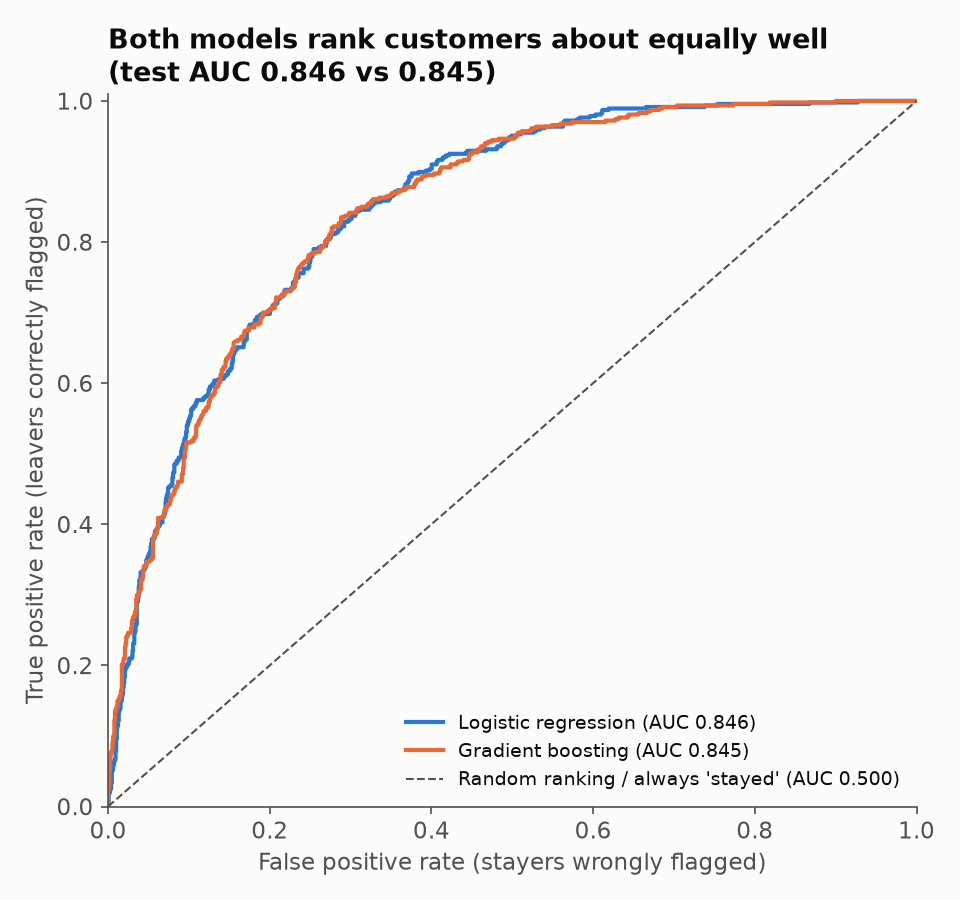

In [16]:
charts.CHART_DIR.mkdir(parents=True, exist_ok=True)
charts.roc_chart(out)
display(Image(filename=str(charts.CHART_DIR / "roc_curves.png")))

### 4.6 Recommendation: logistic regression
The two models rank customers almost identically, on the test split and across the 5 folds (the gap is
smaller than the fold-to-fold spread). When accuracy ties, the simpler model wins. Logistic regression
gives one coefficient per feature that a manager can read, it's cheap to run and audit, and it's easier
to defend to compliance.

### 4.7 Top 10 logistic regression coefficients in plain English
Features were standardised, so each coefficient is the change in the **log-odds of leaving** for one
standard-deviation increase, holding the other features fixed. `exp(coefficient)` is the odds multiplier:
above 1 means more likely to leave, below 1 less likely.

For yes/no features (e.g. Fiber optic vs DSL), one standard deviation isn't the same as "switching
category", so we read those coefficients only for **direction and relative size**, not as literal odds.

In [17]:
top = out["top_coefs"].copy()
refs = model.reference_categories(df)
display(top.round(3))
for _, row in top.iterrows():
    print("-", model.plain_english(row["feature"], row["coefficient"], refs))

,feature,coefficient,odds_multiplier,direction
0,tenure,-1.249,0.287,less likely to leave
1,MonthlyCharges,-0.889,0.411,less likely to leave
2,InternetService_Fiber optic,0.747,2.111,more likely to leave
3,Contract_Two year,-0.559,0.572,less likely to leave
4,TotalCharges,0.542,1.720,more likely to leave
5,Contract_One year,-0.286,0.752,less likely to leave
6,StreamingMovies_Yes,0.267,1.306,more likely to leave
7,StreamingTV_Yes,0.238,1.269,more likely to leave
8,MultipleLines_Yes,0.207,1.230,more likely to leave
9,PaperlessBilling_Yes,0.200,1.221,more likely to leave


- Each extra standard deviation of tenure is linked with lower odds of leaving (odds x 0.29, other features held fixed)
- Each extra standard deviation of MonthlyCharges is linked with lower odds of leaving (odds x 0.41, other features held fixed)
- InternetService = 'Fiber optic' (vs. 'DSL') is linked with higher odds of leaving (coefficient +0.75)
- Contract = 'Two year' (vs. 'Month-to-month') is linked with lower odds of leaving (coefficient -0.56)
- Each extra standard deviation of TotalCharges is linked with higher odds of leaving (odds x 1.72, other features held fixed)
- Contract = 'One year' (vs. 'Month-to-month') is linked with lower odds of leaving (coefficient -0.29)
- StreamingMovies = 'Yes' (vs. 'No') is linked with higher odds of leaving (coefficient +0.27)
- StreamingTV = 'Yes' (vs. 'No') is linked with higher odds of leaving (coefficient +0.24)
- MultipleLines = 'Yes' (vs. 'No') is linked with higher odds of leaving (coefficient +0.21)
- PaperlessBilling = 'Yes' (vs. 'N

**Careful reading:** `tenure`, `MonthlyCharges` and `TotalCharges` overlap heavily (total ≈ tenure ×
monthly). The add-on service columns also explain much of the monthly price. When features overlap, the
model splits credit between them in ways that can look odd: here `MonthlyCharges` comes out *negative*
even though higher-paying customers leave more in the raw data. So these coefficients describe this
model's ranking logic, not the separate effect of each feature, and none of them is causal. The robust
messages are the large, stable ones: longer tenure and longer contracts go with staying, and fiber
internet goes with leaving.

## 5. Charts
This cell saves all five charts to `outputs/charts/` and shows them. Each title states the takeaway, and
every number in a title is computed from the data.

['churn_by_contract.png', 'churn_by_payment.png', 'churn_by_tenure_band.png', 'cohort_vs_baseline.png', 'roc_curves.png']


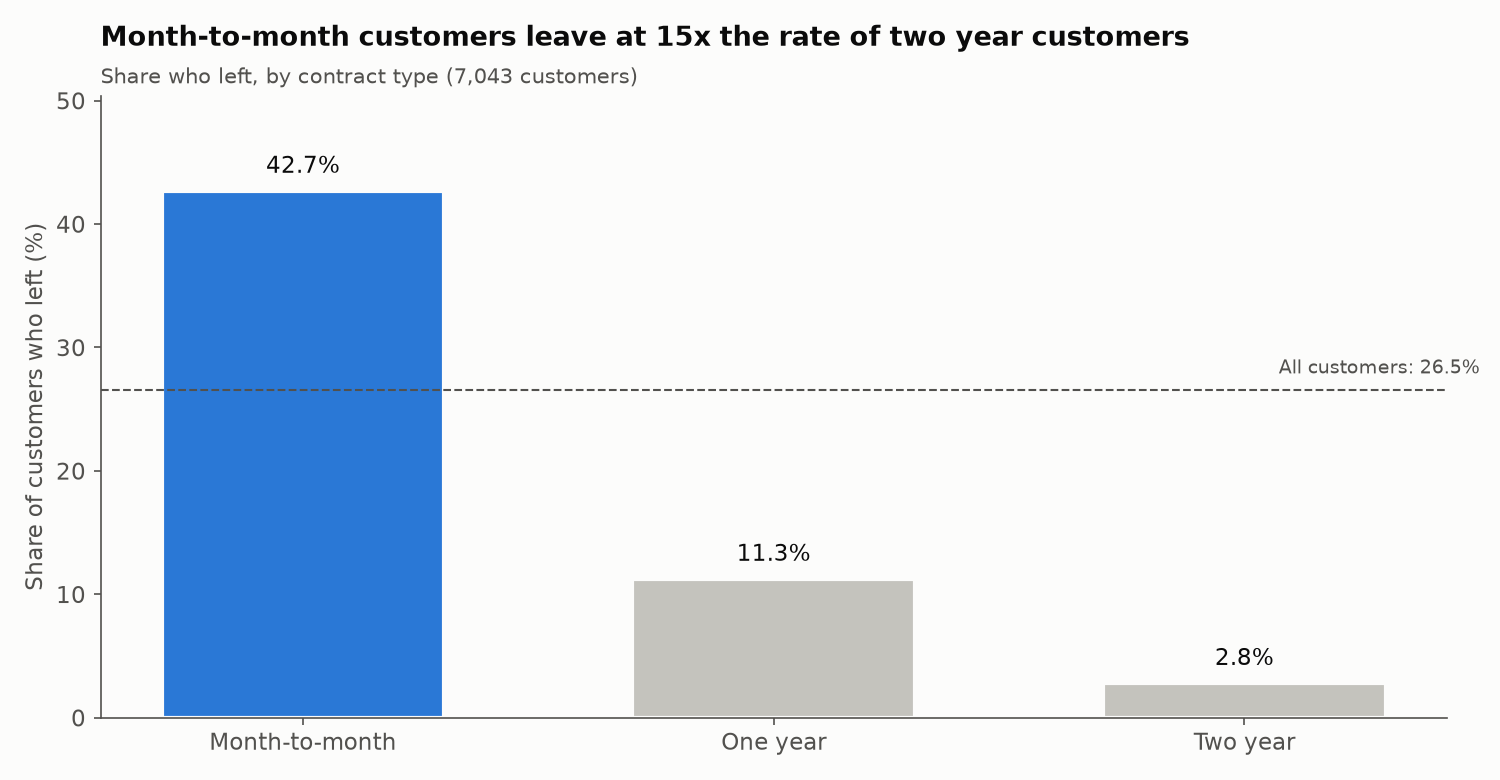

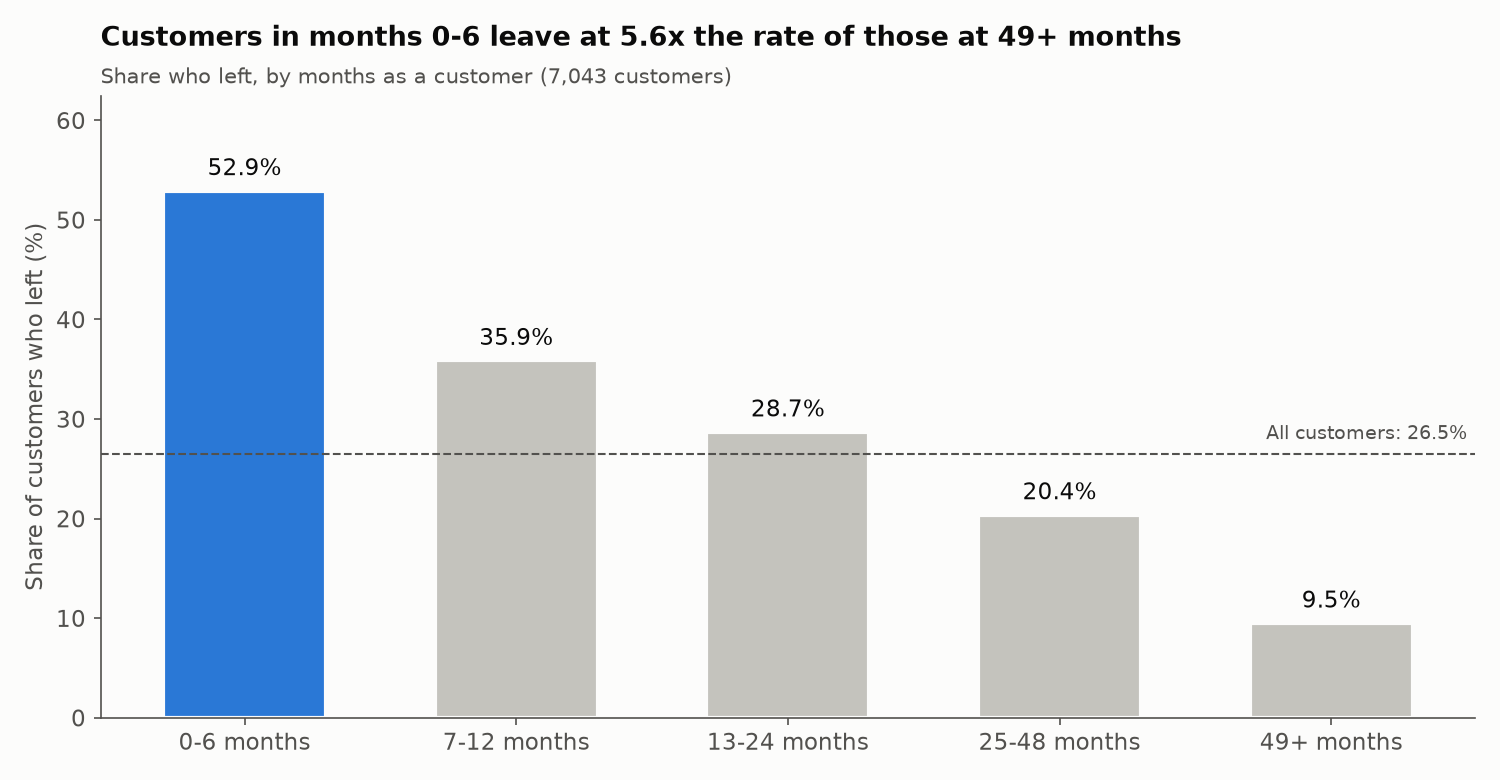

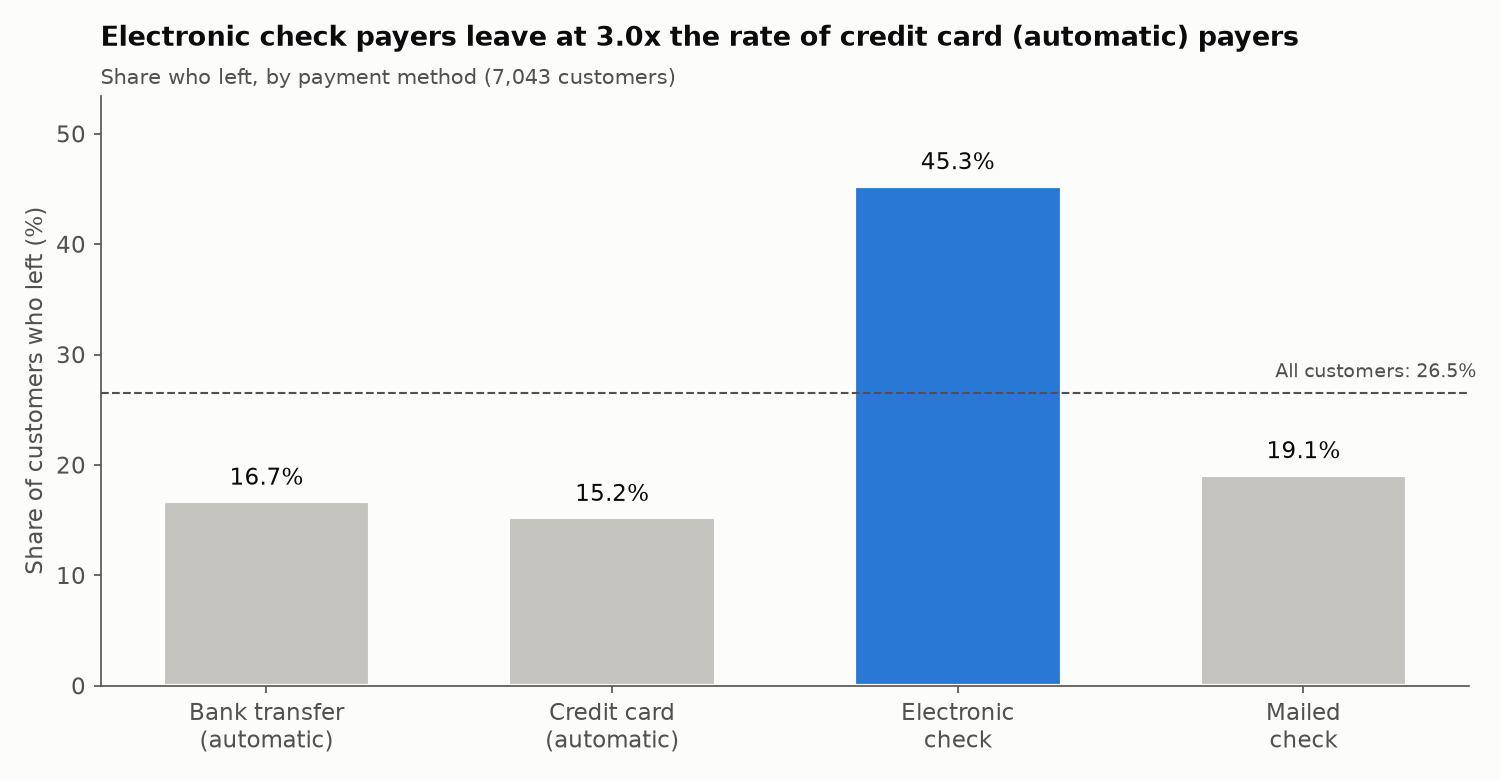

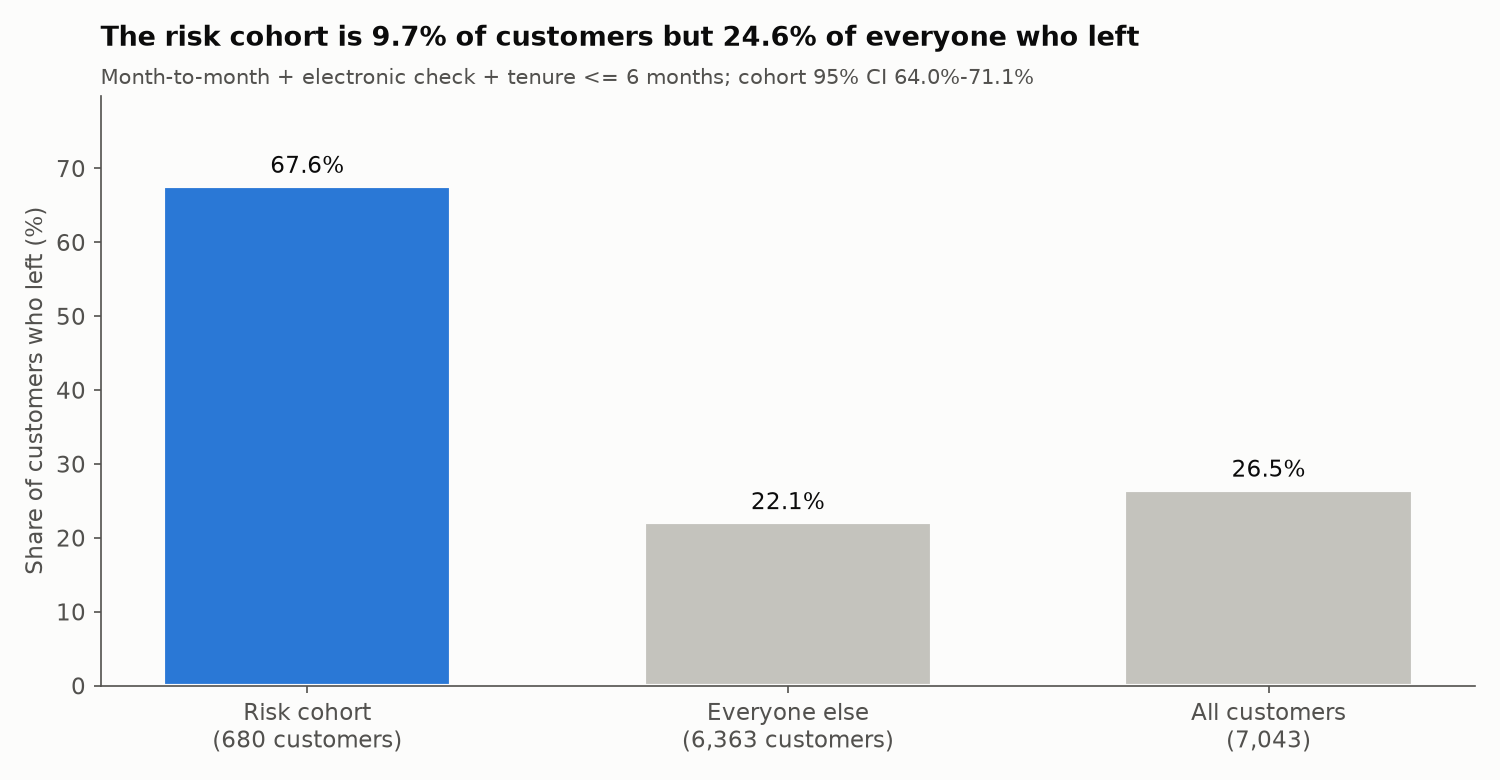

In [18]:
saved = charts.save_all(out)
print(saved)
for name in ["churn_by_contract.png", "churn_by_tenure_band.png", "churn_by_payment.png", "cohort_vs_baseline.png"]:
    display(Image(filename=str(charts.CHART_DIR / name)))

## 6. Business recommendation (a proposal, not yet tested)

**Who to target:** the risk cohort, which is new month-to-month customers paying by electronic check.
It's small enough to treat individually and holds roughly a quarter of all customers who left.

**What to test:** two candidate offers, each against a control group:
1. A **first-90-day retention offer**, such as an onboarding check-in plus a modest bill credit, and
2. A **switch-to-annual incentive**: a discount for moving from month-to-month to a one-year contract.
   (Automatic-payment enrolment could be a further arm.)

**How to measure it:** a **randomized pilot**. New customers who enter the cohort are randomly assigned
to treatment or control. The primary metric is **90-day churn, treatment vs control**. Randomization is
what lets us claim the offer *caused* any difference, which this historical data can't do.

**Guardrails:** the offer must cost less than the margin it saves. Track offer cost per retained customer
and gross margin per customer. Also watch for customers who would have stayed anyway taking the discount.

The cell below sizes the pilot. The target effect (a 10-percentage-point drop) is a **planning
assumption**, not a finding: it's the smallest effect we'd consider worth acting on.

In [19]:
p_control = summary["churn_rate_pct"] / 100       # observed cohort churn rate
assumed_drop = 0.10                               # planning assumption, NOT a finding
per_group = cohort.pilot_customers_per_group(p_control, p_control - assumed_drop)
cohort_monthly = df.loc[cohort.cohort_mask(df), "MonthlyCharges"].mean()

print(f"Control churn assumed = observed cohort rate: {100*p_control:.2f}%")
print(f"Smallest effect worth detecting (assumption): {100*p_control:.2f}% -> {100*(p_control-assumed_drop):.2f}%")
print(f"Customers needed per group (5% significance, 80% power): {per_group:,}  -> {2*per_group:,} in total")
print(f"For scale: today's cohort has {summary['size']:,} customers, so recruitment runs over multiple monthly intakes.")
print(f"Average monthly bill in the cohort: ${cohort_monthly:.2f}")
print("Break-even rule: offer cost per treated customer must be below")
print("  (churn reduction) x (monthly margin) x (extra months retained) -- margin is not in this dataset.")

Control churn assumed = observed cohort rate: 67.65%
Smallest effect worth detecting (assumption): 67.65% -> 57.65%
Customers needed per group (5% significance, 80% power): 367  -> 734 in total
For scale: today's cohort has 680 customers, so recruitment runs over multiple monthly intakes.
Average monthly bill in the cohort: $67.22
Break-even rule: offer cost per treated customer must be below
  (churn reduction) x (monthly margin) x (extra months retained) -- margin is not in this dataset.


## Limitations
- **Snapshot data:** we see one moment in time, not customer histories. We can't see *when* customers left
  or what happened just before.
- **Association only:** every pattern here is a correlation. Only the randomized pilot can measure cause and effect.
- **No cost or margin data:** we can't put a dollar value on churn or on an offer yet.
- **Sample data:** IBM's dataset is a fictional teaching sample, and real numbers would differ.
- **No recommendation has been implemented.** Section 6 is a proposed test.